Samples included: ['E1', 'E2', 'E3-a', 'E4', 'E4-a']


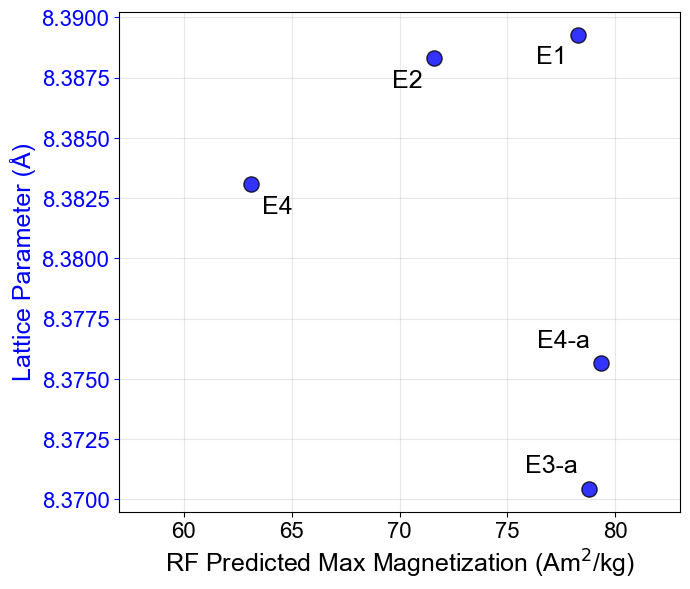

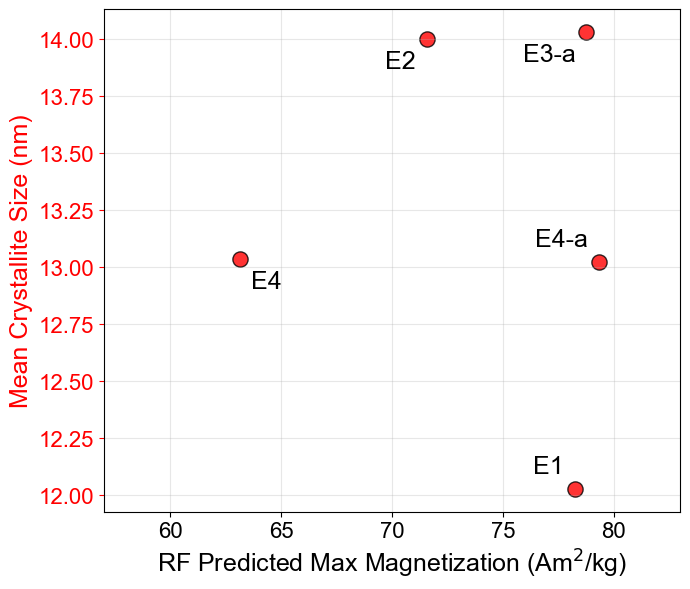

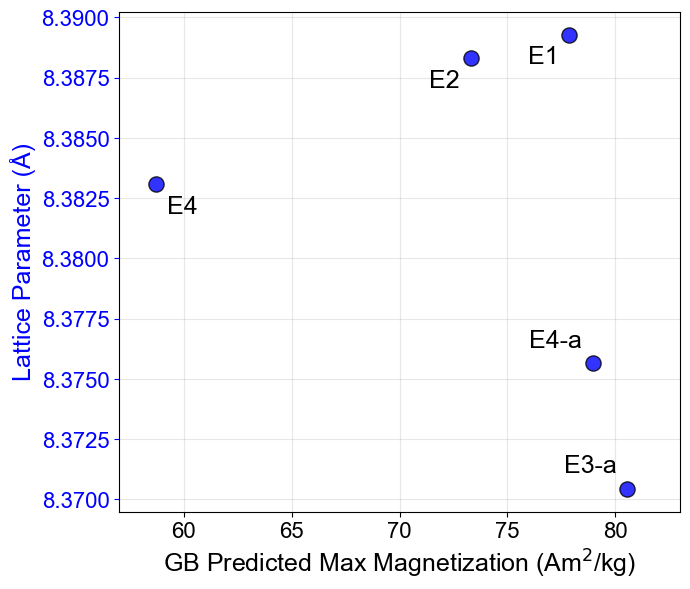

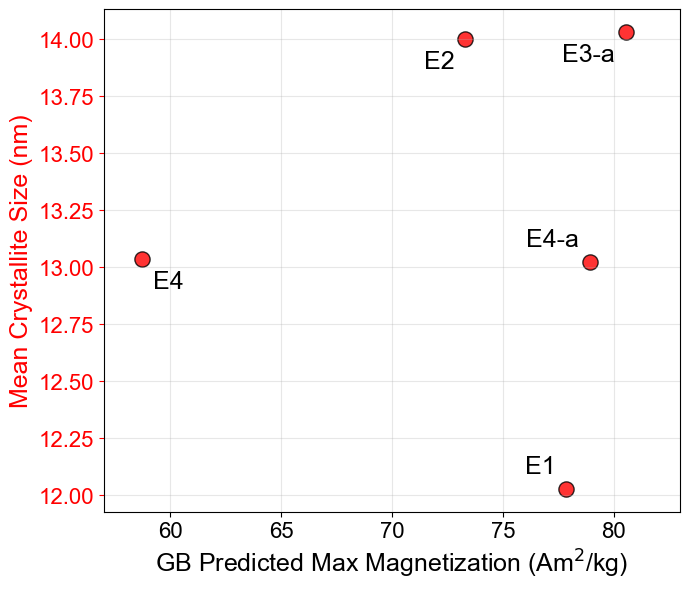

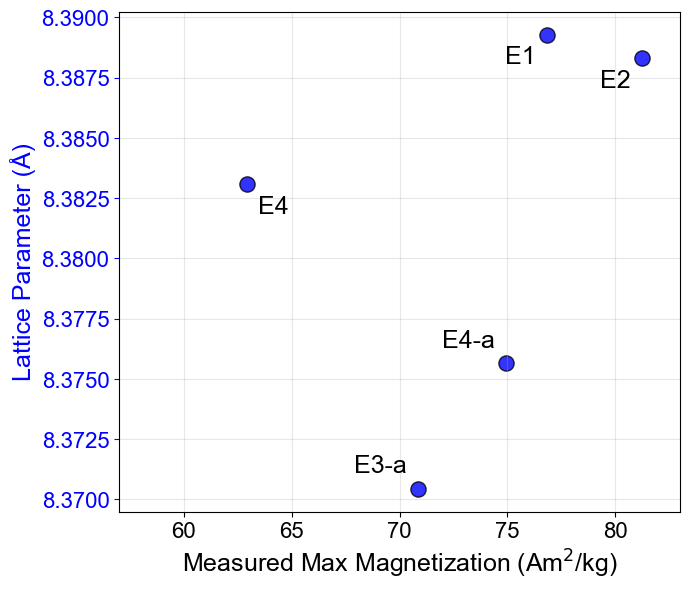

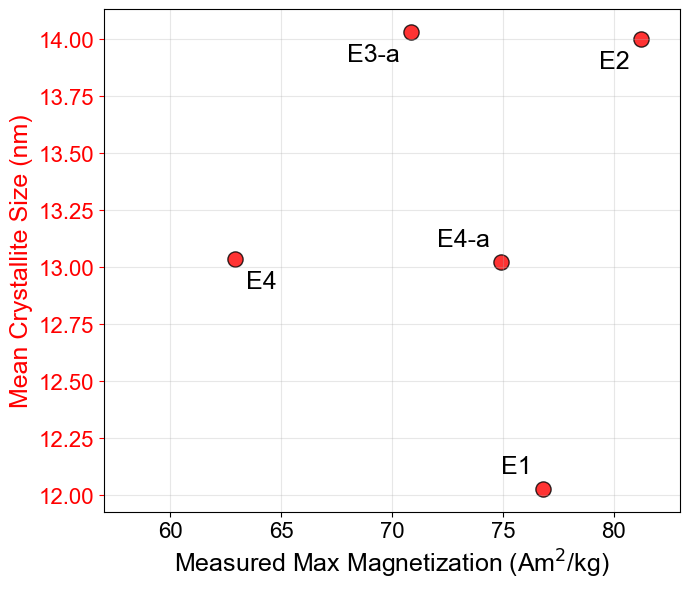

In [10]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# USER DATA CONTROLS
# ============================================================

csv_dir = (
    r"C:\Users\fabel\Documents\Abel_Lab"
    r"\Iron_Oxide_Model_Restructured\Experimental_datasets"
)

csv_filename = (
    "extracted_XRD_values_E1_E2_E3_E4_"
    "Bruker_processed_and_bg_sub.csv"
)

csv_path = os.path.join(csv_dir, csv_filename)

samples_to_plot = ["E1", "E2", "E3-a", "E4", "E4-a"]

xlim_predicted = (57, 83)
xlim_gb_predicted = (57, 83)
xlim_measured = (57, 83)


# ============================================================
# USER PLOT CONTROLS
# ============================================================

# Figure dimensions
figure_size = (7, 6)

# Font controls
font_family = "Arial"
axis_label_fontsize = 18
tick_label_fontsize = 16
sample_label_fontsize = 18
legend_fontsize = 14

axis_label_fontweight = "normal"
sample_label_fontweight = "normal"

# Point colors
lattice_point_color = "b"
crystallite_point_color = "r"

# Point sizes
lattice_point_size = 120
crystallite_point_size = 120

# Point appearance
point_marker = "o"
point_alpha = 0.8
point_edge_color = "k"
point_edge_width = 1.0

sample_label_fontsize = 18
annotation_distance = 8          # Distance from point, in points
annotation_border_padding = 6    # Minimum border clearance, in pixels

# Sample-label position relative to each point
annotation_offset = (6, 6)

# Grid controls
show_grid = True
grid_alpha = 0.3

# Legend controls
show_legend = False
legend_location = "center right"

# Apply the selected font family globally
plt.rcParams["font.family"] = font_family


# ============================================================
# LOAD AND PREPARE DATA
# ============================================================

df = pd.read_csv(csv_path)

# Convert headers to consistent Python-friendly names
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", "_", regex=True)
)

df = df.rename(
    columns={
        "manuscript_sample_names": "sample_name",
        "mean_crystallite_size": "crystallite_size",
        "measure_magnetization": "measured_magnetization",
    }
)

required_columns = {
    "sample_name",
    "lattice_parameter",
    "crystallite_size",
    "measured_magnetization",
    "rf_predicted_magnetization",
    "gb_predicted_magnetization",
}

missing_columns = required_columns.difference(df.columns)

if missing_columns:
    raise KeyError(
        f"Missing columns: {sorted(missing_columns)}\n"
        f"Available columns: {df.columns.tolist()}"
    )

# Clean sample names while preserving missing values
df["sample_name"] = (
    df["sample_name"]
    .astype("string")
    .str.strip()
)

numeric_columns = [
    "lattice_parameter",
    "crystallite_size",
    "measured_magnetization",
    "rf_predicted_magnetization",
    "gb_predicted_magnetization",
]

df[numeric_columns] = df[numeric_columns].apply(
    pd.to_numeric,
    errors="coerce",
)

plot_df = df[
    df["sample_name"].isin(samples_to_plot)
].copy()

print("Samples included:", plot_df["sample_name"].tolist())


# ============================================================
# SINGLE-AXIS PLOTTING FUNCTION
# ============================================================

def annotate_inside_axes(ax, text, x, y):
    """
    Places a sample label near its point and shifts it inward if the
    rendered label crosses an axis border.
    """
    fig = ax.figure

    # Render the current axes so display coordinates are available
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()

    axes_bbox = ax.get_window_extent(renderer=renderer)
    point_x, point_y = ax.transData.transform((x, y))

    # Initially position the label toward the center of the plot
    if point_x > axes_bbox.x0 + axes_bbox.width / 2:
        offset_x = -annotation_distance
        horizontal_alignment = "right"
    else:
        offset_x = annotation_distance
        horizontal_alignment = "left"

    if point_y > axes_bbox.y0 + axes_bbox.height / 2:
        offset_y = -annotation_distance
        vertical_alignment = "top"
    else:
        offset_y = annotation_distance
        vertical_alignment = "bottom"

    annotation = ax.annotate(
        text,
        (x, y),
        xytext=(offset_x, offset_y),
        textcoords="offset points",
        fontsize=sample_label_fontsize,
        fontweight=sample_label_fontweight,
        ha=horizontal_alignment,
        va=vertical_alignment,
    )

    # Render the annotation to measure its actual size
    fig.canvas.draw()
    label_bbox = annotation.get_window_extent(renderer=renderer)

    safe_left = axes_bbox.x0 + annotation_border_padding
    safe_right = axes_bbox.x1 - annotation_border_padding
    safe_bottom = axes_bbox.y0 + annotation_border_padding
    safe_top = axes_bbox.y1 - annotation_border_padding

    shift_x_pixels = 0
    shift_y_pixels = 0

    if label_bbox.x0 < safe_left:
        shift_x_pixels += safe_left - label_bbox.x0

    if label_bbox.x1 > safe_right:
        shift_x_pixels -= label_bbox.x1 - safe_right

    if label_bbox.y0 < safe_bottom:
        shift_y_pixels += safe_bottom - label_bbox.y0

    if label_bbox.y1 > safe_top:
        shift_y_pixels -= label_bbox.y1 - safe_top

    # Annotation offsets use points, so convert pixels to points
    pixels_to_points = 72 / fig.dpi

    annotation.set_position(
        (
            offset_x + shift_x_pixels * pixels_to_points,
            offset_y + shift_y_pixels * pixels_to_points,
        )
    )

    return annotation

def make_single_axis_plot(
    df_in,
    x_col,
    y_col,
    x_label,
    y_label,
    point_color,
    point_size,
    xlim=None,
):
    plot_data = df_in.dropna(
        subset=[x_col, y_col]
    ).copy()

    fig, ax = plt.subplots(figsize=figure_size)

    ax.scatter(
        plot_data[x_col],
        plot_data[y_col],
        color=point_color,
        s=point_size,
        marker=point_marker,
        alpha=point_alpha,
        edgecolor=point_edge_color,
        linewidth=point_edge_width,
        label=y_label,
    )

    

    # Axis labels
    ax.set_xlabel(
        x_label,
        fontsize=axis_label_fontsize,
        fontweight=axis_label_fontweight,
    )

    ax.set_ylabel(
        y_label,
        fontsize=axis_label_fontsize,
        fontweight=axis_label_fontweight,
        color=point_color,
    )

    # Tick formatting
    ax.tick_params(
        axis="x",
        labelsize=tick_label_fontsize,
    )

    ax.tick_params(
        axis="y",
        labelsize=tick_label_fontsize,
        colors=point_color,
    )

    # X-axis limits
    if xlim is not None:
        ax.set_xlim(*xlim)

    # Optional legend
    if show_legend:
        ax.legend(
            fontsize=legend_fontsize,
            frameon=True,
            loc=legend_location,
        )

    # Optional grid
    if show_grid:
        ax.grid(alpha=grid_alpha)


    fig.tight_layout()

    # Add labels after the final axis dimensions have been established
    for _, row in plot_data.iterrows():
        annotate_inside_axes(
            ax,
            text=row["sample_name"],
            x=row[x_col],
            y=row[y_col],
        )

    plt.show()

# ============================================================
# PLOT 1
# Lattice parameter vs. RF-predicted magnetization
# ============================================================

make_single_axis_plot(
    plot_df,
    x_col="rf_predicted_magnetization",
    y_col="lattice_parameter",
    x_label="RF Predicted Max Magnetization (Am$^2$/kg)",
    y_label="Lattice Parameter (Å)",
    point_color=lattice_point_color,
    point_size=lattice_point_size,
    xlim=xlim_predicted,
)


# ============================================================
# PLOT 2
# Crystallite size vs. RF-predicted magnetization
# ============================================================

make_single_axis_plot(
    plot_df,
    x_col="rf_predicted_magnetization",
    y_col="crystallite_size",
    x_label="RF Predicted Max Magnetization (Am$^2$/kg)",
    y_label="Mean Crystallite Size (nm)",
    point_color=crystallite_point_color,
    point_size=crystallite_point_size,
    xlim=xlim_predicted,
)


# ============================================================
# PLOT 3
# Lattice parameter vs. GB-predicted magnetization
# ============================================================

make_single_axis_plot(
    plot_df,
    x_col="gb_predicted_magnetization",
    y_col="lattice_parameter",
    x_label="GB Predicted Max Magnetization (Am$^2$/kg)",
    y_label="Lattice Parameter (Å)",
    point_color=lattice_point_color,
    point_size=lattice_point_size,
    xlim=xlim_gb_predicted,
)


# ============================================================
# PLOT 4
# Crystallite size vs. GB-predicted magnetization
# ============================================================

make_single_axis_plot(
    plot_df,
    x_col="gb_predicted_magnetization",
    y_col="crystallite_size",
    x_label="GB Predicted Max Magnetization (Am$^2$/kg)",
    y_label="Mean Crystallite Size (nm)",
    point_color=crystallite_point_color,
    point_size=crystallite_point_size,
    xlim=xlim_gb_predicted,
)


# ============================================================
# PLOT 5
# Lattice parameter vs. measured magnetization
# ============================================================

make_single_axis_plot(
    plot_df,
    x_col="measured_magnetization",
    y_col="lattice_parameter",
    x_label="Measured Max Magnetization (Am$^2$/kg)",
    y_label="Lattice Parameter (Å)",
    point_color=lattice_point_color,
    point_size=lattice_point_size,
    xlim=xlim_measured,
)


# ============================================================
# PLOT 6
# Crystallite size vs. measured magnetization
# ============================================================

make_single_axis_plot(
    plot_df,
    x_col="measured_magnetization",
    y_col="crystallite_size",
    x_label="Measured Max Magnetization (Am$^2$/kg)",
    y_label="Mean Crystallite Size (nm)",
    point_color=crystallite_point_color,
    point_size=crystallite_point_size,
    xlim=xlim_measured,
)